In [1]:
# ===== HW2 setup =====
import os
import numpy as np
import matplotlib.pyplot as plt
import sklearn

SEED = 42                              # one seed number, reused everywhere
rng = np.random.default_rng(SEED)      # random-number generator started from that seed
os.makedirs("figures", exist_ok=True)  # folder for saved figures

# Sunset palette, used in every figure
CLASS_COLORS = {0: "#7A1E6C",   # class 0: deep magenta-purple
                1: "#F7A541"}   # class 1: warm amber-orange
SUNSET_CMAP = "plasma"          # purple -> magenta -> orange -> yellow, for backgrounds later

print(f"scikit-learn version: {sklearn.__version__}")

scikit-learn version: 1.9.1


Linear:   (10000, 2) (10000,)
Circular: (10000, 2) (10000,)


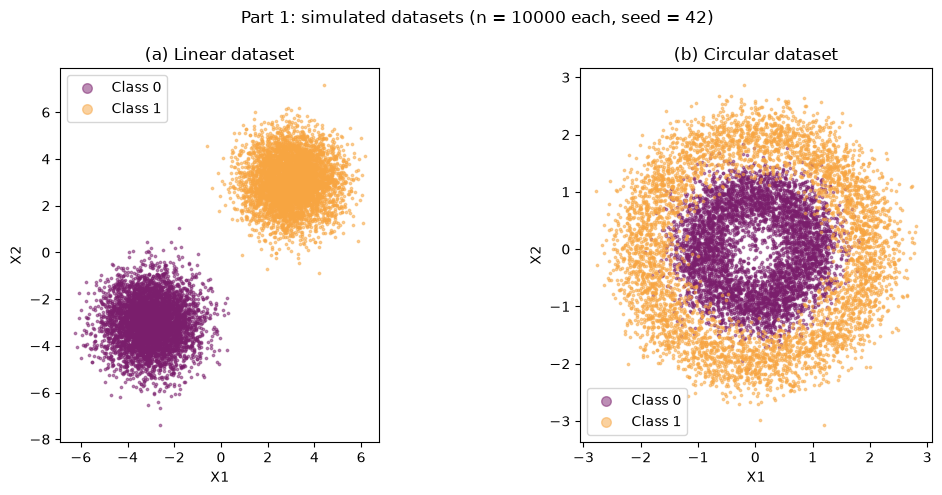

In [2]:
# ===== Part 1: simulate two 2-D datasets =====
n = 10_000
n_per_class = n // 2

# ---------- (a) Linear dataset: two far-apart Gaussian blobs ----------
class0_lin = rng.normal(loc=[-3, -3], scale=1.0, size=(n_per_class, 2))
class1_lin = rng.normal(loc=[ 3,  3], scale=1.0, size=(n_per_class, 2))
X_lin = np.vstack([class0_lin, class1_lin])
y_lin = np.concatenate([np.zeros(n_per_class), np.ones(n_per_class)])

# ---------- (b) Circular dataset: a ring inside a ring ----------
def make_ring(n_points, radius, noise_sd):
    """Return n_points scattered around a circle of the given radius."""
    angle = rng.uniform(0, 2 * np.pi, size=n_points)
    r = rng.normal(loc=radius, scale=noise_sd, size=n_points)
    return np.column_stack([r * np.cos(angle), r * np.sin(angle)])

class0_circ = make_ring(n_per_class, radius=1.0, noise_sd=0.3)   # inner ring
class1_circ = make_ring(n_per_class, radius=2.0, noise_sd=0.3)   # CHANGED: outer ring now at 2, so the edges overlap
X_circ = np.vstack([class0_circ, class1_circ])
y_circ = np.concatenate([np.zeros(n_per_class), np.ones(n_per_class)])

print("Linear:  ", X_lin.shape, y_lin.shape)
print("Circular:", X_circ.shape, y_circ.shape)

# ---------- Plot both datasets side by side ----------
fig, axes = plt.subplots(1, 2, figsize=(11, 5))

panels = [(axes[0], X_lin,  y_lin,  "(a) Linear dataset"),
          (axes[1], X_circ, y_circ, "(b) Circular dataset")]

for ax, X, y, title in panels:                 # CHANGED: one loop draws both panels the same way
    for label in [0, 1]:
        ax.scatter(X[y == label, 0], X[y == label, 1],
                   s=3, alpha=0.5, color=CLASS_COLORS[label],   
                   label=f"Class {label}")
    ax.set_title(title)
    ax.set_xlabel("X1")
    ax.set_ylabel("X2")
    ax.set_aspect("equal")
    ax.legend(markerscale=4)

fig.suptitle(f"Part 1: simulated datasets (n = {n} each, seed = {SEED})")
fig.tight_layout()
fig.savefig("figures/part1_datasets.png", dpi=300)
plt.show()

In [3]:
# ===== Train/test split (used in Parts 2-6) =====
from sklearn.model_selection import train_test_split

TEST_SIZE = 0.3   # 30% of points held out for testing

# Linear dataset: X = inputs, y = labels; the function returns 4 pieces in this order
X_lin_train, X_lin_test, y_lin_train, y_lin_test = train_test_split(
    X_lin, y_lin,
    test_size=TEST_SIZE,
    random_state=SEED,   # same split every run
    stratify=y_lin)      # keep the 50/50 class balance in both pieces

# Circular dataset: same recipe
X_circ_train, X_circ_test, y_circ_train, y_circ_test = train_test_split(
    X_circ, y_circ,
    test_size=TEST_SIZE,
    random_state=SEED,
    stratify=y_circ)

# Sanity check: sizes and class balance
for name, y_tr, y_te in [("Linear", y_lin_train, y_lin_test),
                         ("Circular", y_circ_train, y_circ_test)]:
    print(f"{name}: train = {len(y_tr)} points ({y_tr.mean():.0%} class 1), "
          f"test = {len(y_te)} points ({y_te.mean():.0%} class 1)")

Linear: train = 7000 points (50% class 1), test = 3000 points (50% class 1)
Circular: train = 7000 points (50% class 1), test = 3000 points (50% class 1)


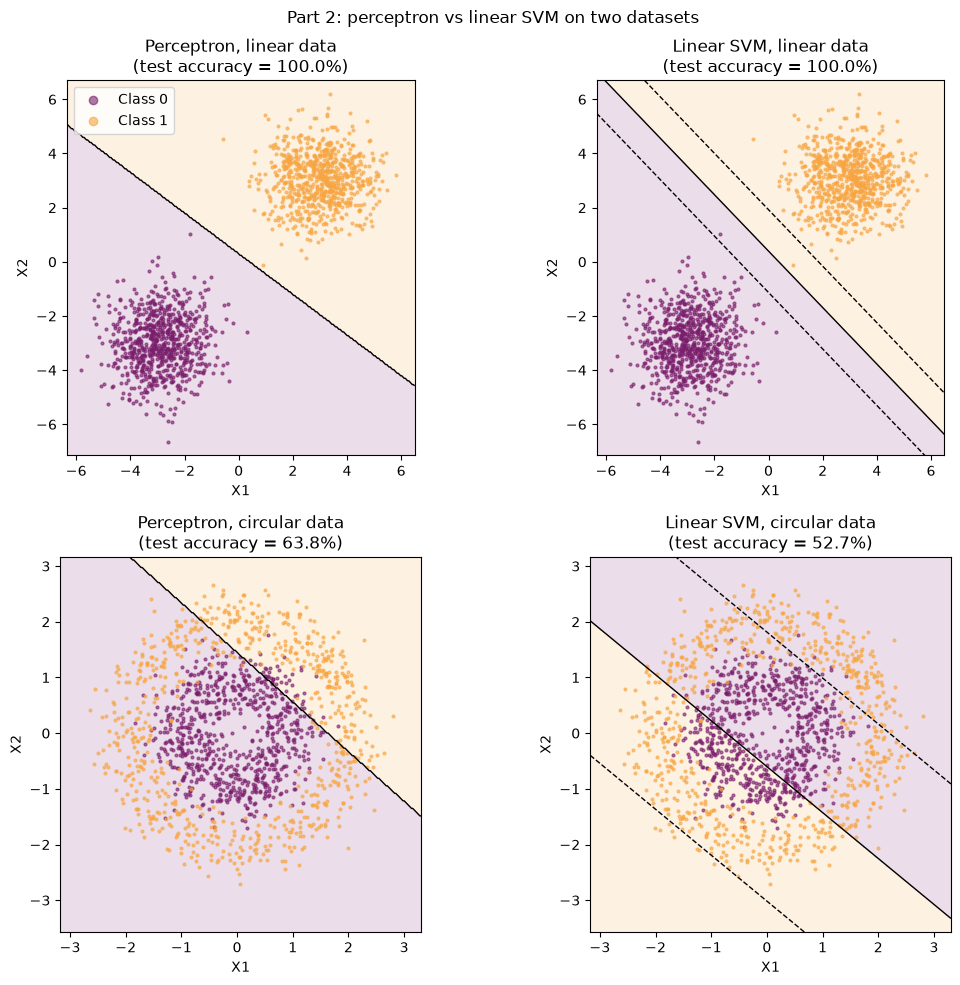

 Dataset      Model  Train accuracy  Test accuracy
  Linear Perceptron           1.000          1.000
  Linear Linear SVM           1.000          1.000
Circular Perceptron           0.621          0.638
Circular Linear SVM           0.559          0.527


In [4]:
# ===== Part 2: perceptron vs linear SVM =====
import pandas as pd
from sklearn.linear_model import Perceptron
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

def plot_decision_boundary(ax, model, X, y, title, show_margin=False, n_show=1500):
    """Colour the plane by the model's prediction and overlay test points."""
    # 1) a fine grid of points covering the plot area
    x1_min, x1_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    x2_min, x2_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx1, xx2 = np.meshgrid(np.linspace(x1_min, x1_max, 300),
                           np.linspace(x2_min, x2_max, 300))
    grid = np.column_stack([xx1.ravel(), xx2.ravel()])   # 90,000 grid points as a (90000, 2) table

    # 2) predict the class at every grid point -> shaded regions
    Z = model.predict(grid).reshape(xx1.shape)
    ax.contourf(xx1, xx2, Z, levels=[-0.5, 0.5, 1.5],
                colors=[CLASS_COLORS[0], CLASS_COLORS[1]], alpha=0.15)

    # 3) the boundary line (and, for the SVM, the margin edges)
    if show_margin:
        D = model.decision_function(grid).reshape(xx1.shape)   # signed distance-like score
        ax.contour(xx1, xx2, D, levels=[-1, 0, 1], colors="k",
                   linestyles=["--", "-", "--"], linewidths=1)
    else:
        ax.contour(xx1, xx2, Z, levels=[0.5], colors="k", linewidths=1)

    # 4) a random subset of test points, so the plot isn't a solid blob
    idx = np.random.default_rng(SEED).choice(len(y), size=min(n_show, len(y)), replace=False)
    for label in [0, 1]:
        pts = idx[y[idx] == label]
        ax.scatter(X[pts, 0], X[pts, 1], s=4, alpha=0.6,
                   color=CLASS_COLORS[label], label=f"Class {label}")
    ax.set_title(title)
    ax.set_xlabel("X1")
    ax.set_ylabel("X2")
    ax.set_aspect("equal")

datasets = {"Linear":   (X_lin_train,  X_lin_test,  y_lin_train,  y_lin_test),
            "Circular": (X_circ_train, X_circ_test, y_circ_train, y_circ_test)}

results = []
fig, axes = plt.subplots(2, 2, figsize=(11, 10))   # rows = datasets, columns = models

for row, (data_name, (X_tr, X_te, y_tr, y_te)) in enumerate(datasets.items()):
    models = {"Perceptron": Perceptron(max_iter=1000, random_state=SEED),
              "Linear SVM": SVC(kernel="linear", C=1.0)}
    for col, (model_name, model) in enumerate(models.items()):
        model.fit(X_tr, y_tr)                                  # learn w and b from the training set only
        train_acc = accuracy_score(y_tr, model.predict(X_tr))
        test_acc  = accuracy_score(y_te, model.predict(X_te))  # the score that counts
        results.append({"Dataset": data_name, "Model": model_name,
                        "Train accuracy": round(train_acc, 3),
                        "Test accuracy": round(test_acc, 3)})
        plot_decision_boundary(axes[row, col], model, X_te, y_te,
                               f"{model_name}, {data_name.lower()} data\n(test accuracy = {test_acc:.1%})",
                               show_margin=(model_name == "Linear SVM"))

axes[0, 0].legend(markerscale=3, loc="upper left")
fig.suptitle("Part 2: perceptron vs linear SVM on two datasets")
fig.tight_layout()
fig.savefig("Figures/part2_perceptron_vs_svm.png", dpi=300)
plt.show()

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

Number of support vectors: 3 (out of 7000 training points)


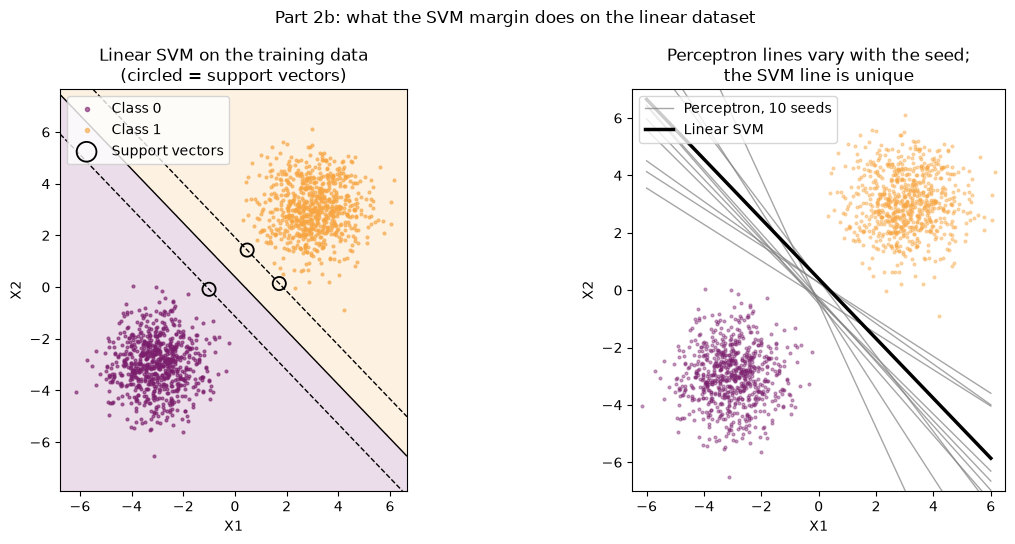

In [5]:
# ===== Part 2b: support vectors, and how stable each model's line is =====
svm_lin = SVC(kernel="linear", C=1.0).fit(X_lin_train, y_lin_train)
print(f"Number of support vectors: {len(svm_lin.support_vectors_)} (out of {len(y_lin_train)} training points)")

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))

# ---- Left: SVM on the TRAINING data, support vectors circled ----
ax = axes[0]
plot_decision_boundary(ax, svm_lin, X_lin_train, y_lin_train,
                       "Linear SVM on the training data\n(circled = support vectors)",
                       show_margin=True)
sv = svm_lin.support_vectors_
ax.scatter(sv[:, 0], sv[:, 1], s=90, facecolors="none", edgecolors="k",
           linewidths=1.3, label="Support vectors")
ax.legend(markerscale=1.5, loc="upper left")

# ---- Right: perceptron retrained with 10 different seeds vs the one SVM line ----
ax = axes[1]
x1_line = np.linspace(-6, 6, 200)

def boundary_x2(model, x1):
    """Solve w1*X1 + w2*X2 + b = 0 for X2."""
    w1, w2 = model.coef_[0]
    b = model.intercept_[0]
    return -(w1 * x1 + b) / w2

idx = np.random.default_rng(SEED).choice(len(y_lin_train), size=1500, replace=False)
for label in [0, 1]:
    pts = idx[y_lin_train[idx] == label]
    ax.scatter(X_lin_train[pts, 0], X_lin_train[pts, 1], s=4, alpha=0.4,
               color=CLASS_COLORS[label])

for s in range(10):    # same data, different random visiting order each time
    p = Perceptron(max_iter=1000, random_state=s).fit(X_lin_train, y_lin_train)
    ax.plot(x1_line, boundary_x2(p, x1_line), color="gray", alpha=0.7, lw=1,
            label="Perceptron, 10 seeds" if s == 0 else None)

ax.plot(x1_line, boundary_x2(svm_lin, x1_line), color="k", lw=2.5, label="Linear SVM")
ax.set_xlim(-6.5, 6.5)
ax.set_ylim(-7, 7)
ax.set_aspect("equal")
ax.set_xlabel("X1")
ax.set_ylabel("X2")
ax.set_title("Perceptron lines vary with the seed;\nthe SVM line is unique")
ax.legend(loc="upper left")

fig.suptitle("Part 2b: what the SVM margin does on the linear dataset")
fig.tight_layout()
fig.savefig("Figures/part2b_margin_and_stability.png", dpi=300)
plt.show()

Polynomial: grid search done in 7 s
RBF: grid search done in 7 s
    Kernel                       Best settings CV accuracy (mean ± SD)  Train acc  Test acc  Precision  Recall    F1   AUC  Support vectors
Polynomial {'C': 0.1, 'coef0': 1, 'degree': 3}           0.948 ± 0.005      0.949     0.950      0.951   0.949 0.950 0.990             1065
       RBF               {'C': 10, 'gamma': 1}           0.949 ± 0.004      0.949     0.951      0.944   0.958 0.951 0.987              914


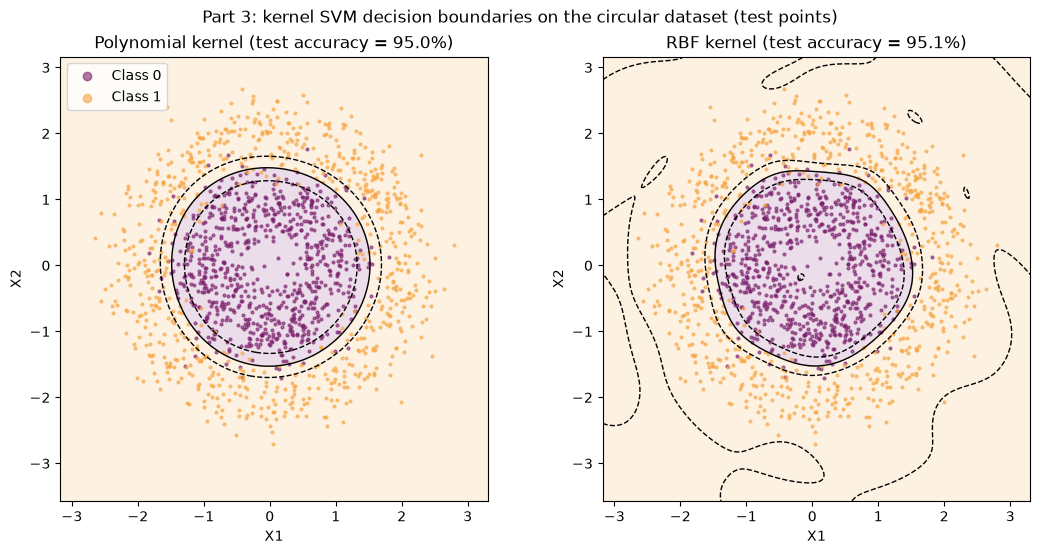

In [6]:
# ===== Part 3: kernel SVMs on the circular dataset =====
import time
from matplotlib.colors import LinearSegmentedColormap
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay)

# ---- 1) Settings to try for each kernel ----
param_grids = {
    "Polynomial": {"kernel": ["poly"], "degree": [2, 3], "coef0": [1], "C": [0.1, 1, 10]},
    "RBF":        {"kernel": ["rbf"],  "gamma": [0.1, 1, 10],          "C": [0.1, 1, 10]},
}

best_models, rows = {}, []
for name, grid in param_grids.items():
    start = time.time()
    search = GridSearchCV(SVC(), grid, cv=5, scoring="accuracy", n_jobs=-1)  # n_jobs=-1: use all CPU cores
    search.fit(X_circ_train, y_circ_train)          # cross-validation happens inside the TRAINING set only
    model = search.best_estimator_                  # best settings, refit on the full training set
    best_models[name] = model

    i = search.best_index_                          # where the best combination sits in the results
    cv_mean = search.cv_results_["mean_test_score"][i]
    cv_sd   = search.cv_results_["std_test_score"][i]

    y_pred  = model.predict(X_circ_test)
    y_score = model.decision_function(X_circ_test)  # continuous score -> needed for ROC/AUC
    rows.append({
        "Kernel": name,
        "Best settings": {k: v for k, v in search.best_params_.items() if k != "kernel"},
        "CV accuracy (mean ± SD)": f"{cv_mean:.3f} ± {cv_sd:.3f}",
        "Train acc": round(accuracy_score(y_circ_train, model.predict(X_circ_train)), 3),
        "Test acc":  round(accuracy_score(y_circ_test, y_pred), 3),
        "Precision": round(precision_score(y_circ_test, y_pred), 3),
        "Recall":    round(recall_score(y_circ_test, y_pred), 3),
        "F1":        round(f1_score(y_circ_test, y_pred), 3),
        "AUC":       round(roc_auc_score(y_circ_test, y_score), 3),
        "Support vectors": int(model.n_support_.sum()),
    })
    print(f"{name}: grid search done in {time.time() - start:.0f} s")

part3_df = pd.DataFrame(rows)
print(part3_df.to_string(index=False))

# ---- 2) Figure A: decision boundaries ----
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
for ax, (name, model) in zip(axes, best_models.items()):
    acc = accuracy_score(y_circ_test, model.predict(X_circ_test))
    plot_decision_boundary(ax, model, X_circ_test, y_circ_test,
                           f"{name} kernel (test accuracy = {acc:.1%})", show_margin=True)
axes[0].legend(markerscale=3, loc="upper left")
fig.suptitle("Part 3: kernel SVM decision boundaries on the circular dataset (test points)")
fig.tight_layout()
fig.savefig("Figures/part3_kernel_boundaries.png", dpi=300)
plt.show()


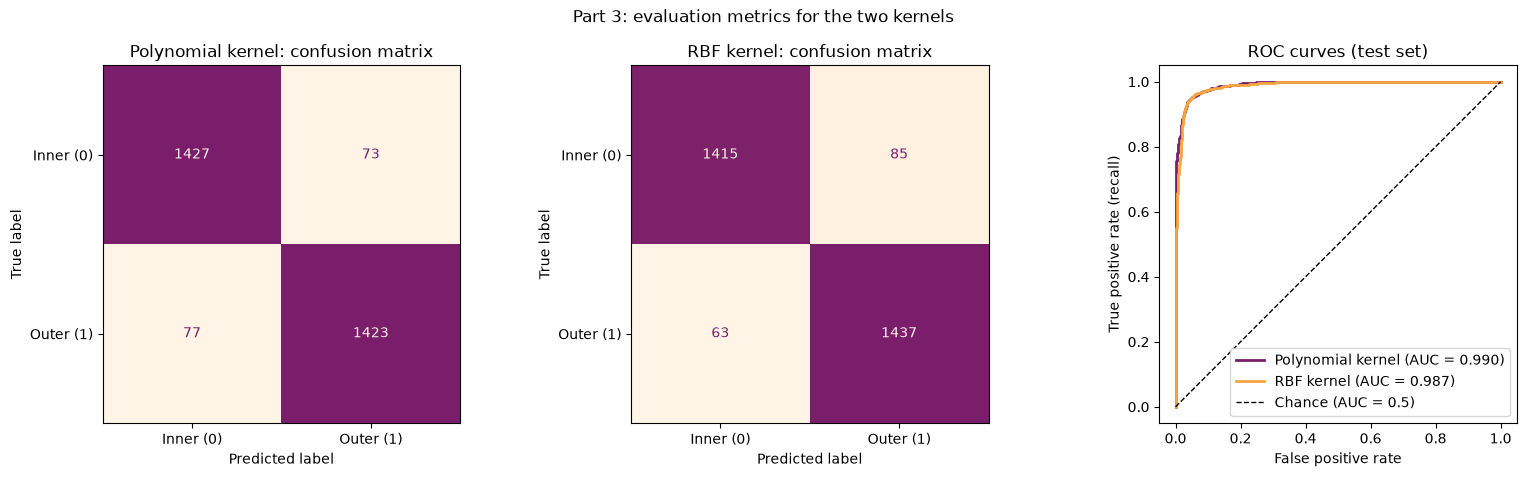

In [7]:
# ===== Part 3b: confusion matrices + ROC curves =====
from sklearn.metrics import roc_curve

sunset_cmap = LinearSegmentedColormap.from_list("sunset", ["#FFF4E6", CLASS_COLORS[1], CLASS_COLORS[0]])
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

# Confusion matrices (one per kernel)
for ax, (name, model) in zip(axes[:2], best_models.items()):
    ConfusionMatrixDisplay.from_estimator(model, X_circ_test, y_circ_test, ax=ax,
                                          cmap=sunset_cmap, colorbar=False,
                                          display_labels=["Inner (0)", "Outer (1)"])
    ax.set_title(f"{name} kernel: confusion matrix")

# ROC curves, drawn by hand
roc_colors = {"Polynomial": CLASS_COLORS[0], "RBF": CLASS_COLORS[1]}
ax = axes[2]
for name, model in best_models.items():
    y_score = model.decision_function(X_circ_test)          # continuous score for each test point
    fpr, tpr, _ = roc_curve(y_circ_test, y_score)           # sweep the threshold -> (FPR, TPR) pairs
    auc = roc_auc_score(y_circ_test, y_score)
    ax.plot(fpr, tpr, color=roc_colors[name], lw=2, label=f"{name} kernel (AUC = {auc:.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Chance (AUC = 0.5)")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate (recall)")
ax.set_title("ROC curves (test set)")
ax.set_aspect("equal")
ax.legend(loc="lower right")

fig.suptitle("Part 3: evaluation metrics for the two kernels")
fig.tight_layout()
fig.savefig("Figures/part3_kernel_metrics.png", dpi=300)
plt.show()

In [8]:
# ===== Part 4a: data augmentation (compute) =====
from sklearn.metrics import f1_score

rbf_best = best_models["RBF"]                                                  # gamma = 1, C = 10 from Part 3
rbf_overfit = SVC(kernel="rbf", gamma=50, C=10).fit(X_circ_train, y_circ_train)  # tiny bumps, on purpose

def ideal_circle_rule(X):
    """Reference classifier: the true border, X1^2 + X2^2 > 1.5^2."""
    return (X[:, 0]**2 + X[:, 1]**2 > 1.5**2).astype(float)

predictors = {"RBF best (γ = 1)":     rbf_best.predict,
              "RBF overfit (γ = 50)": rbf_overfit.predict,
              "Ideal circle rule":    ideal_circle_rule}

# ---- Clean baseline: before any augmentation ----
baseline_df = pd.DataFrame([
    {"Model": name,
     "Train acc":      round(accuracy_score(y_circ_train, predict(X_circ_train)), 3),
     "Clean test acc": round(accuracy_score(y_circ_test,  predict(X_circ_test)),  3)}
    for name, predict in predictors.items()])
print(baseline_df.to_string(index=False), "\n")

# ---- Augmentation: steps a-c from the assignment ----
NOISE_SD = {"Low": 0.1, "High": 0.5}   # SD of the Gaussian nudge
K = 2000                               # number of augmented datasets per noise level
N_SAMPLE = 1000                        # points per augmented dataset
aug_rng = np.random.default_rng(SEED)

records = []
start = time.time()
for level, sd in NOISE_SD.items():
    for k in range(K):
        idx   = aug_rng.choice(len(y_circ_test), size=N_SAMPLE, replace=False)  # a) sample 1,000 test points
        X_aug = X_circ_test[idx] + aug_rng.normal(0, sd, size=(N_SAMPLE, 2))    # b) nudge each point randomly
        y_aug = y_circ_test[idx]                                                #    labels stay the same
        for name, predict in predictors.items():
            y_pred = predict(X_aug)
            records.append({"Noise": level, "Repeat": k, "Model": name,
                            "Accuracy": accuracy_score(y_aug, y_pred),
                            "F1":       f1_score(y_aug, y_pred)})
    print(f"{level} noise done ({time.time() - start:.0f} s so far)")         # c) repeated K times

aug_df = pd.DataFrame(records)
summary = aug_df.groupby(["Model", "Noise"], sort=False)[["Accuracy", "F1"]].agg(["mean", "std"]).round(3)
print("\n", summary)

               Model  Train acc  Clean test acc
    RBF best (γ = 1)      0.949           0.951
RBF overfit (γ = 50)      0.960           0.943
   Ideal circle rule      0.947           0.950 

Low noise done (408 s so far)
High noise done (759 s so far)

                            Accuracy            F1       
                               mean    std   mean    std
Model                Noise                              
RBF best (γ = 1)     Low      0.940  0.007  0.940  0.007
RBF overfit (γ = 50) Low      0.933  0.007  0.933  0.007
Ideal circle rule    Low      0.940  0.007  0.940  0.007
RBF best (γ = 1)     High     0.794  0.012  0.804  0.013
RBF overfit (γ = 50) High     0.792  0.012  0.802  0.013
Ideal circle rule    High     0.795  0.012  0.804  0.013


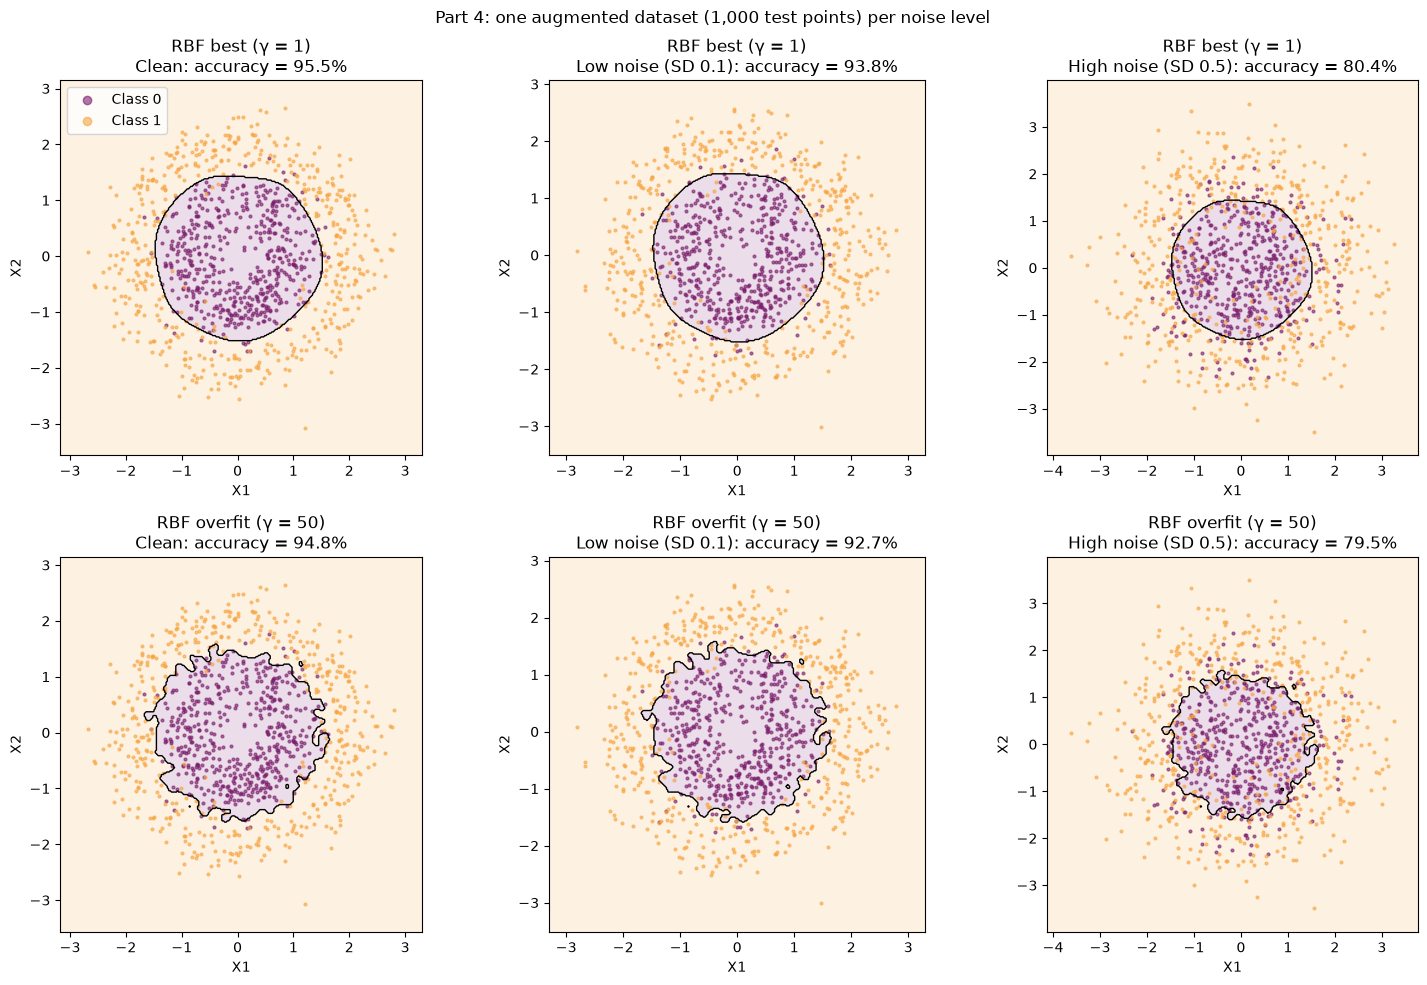

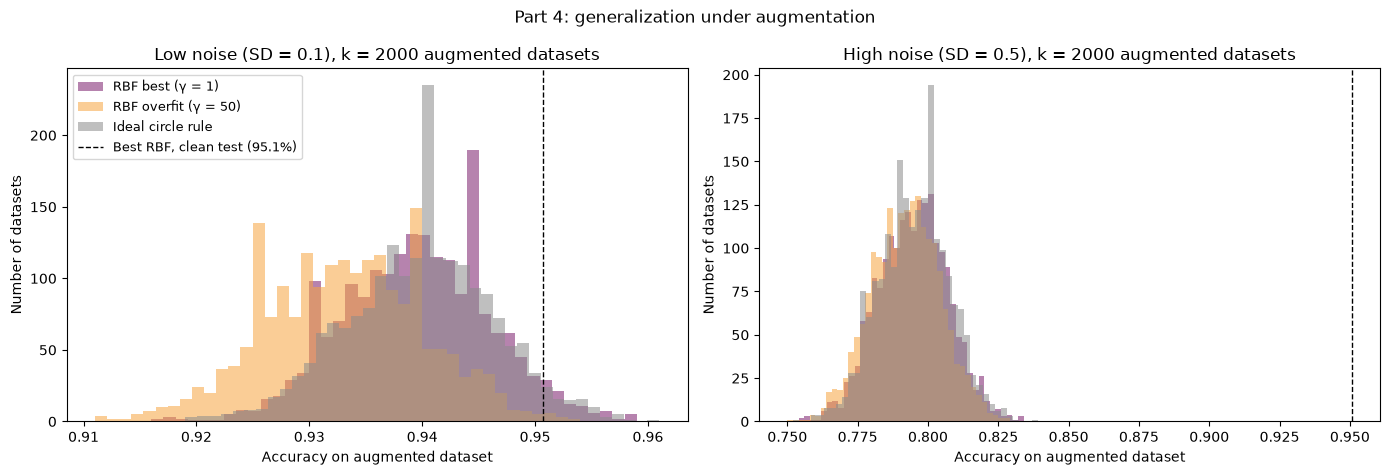

In [9]:
# ===== Part 4b: augmentation figures =====
# ---- Figure A: one example augmented dataset per noise level, for both RBF models ----
example_rng = np.random.default_rng(SEED)
idx  = example_rng.choice(len(y_circ_test), size=N_SAMPLE, replace=False)
X_ex = X_circ_test[idx]
y_ex = y_circ_test[idx]
examples = {"Clean":               X_ex,
            "Low noise (SD 0.1)":  X_ex + example_rng.normal(0, 0.1, size=X_ex.shape),
            "High noise (SD 0.5)": X_ex + example_rng.normal(0, 0.5, size=X_ex.shape)}
models4 = {"RBF best (γ = 1)": rbf_best, "RBF overfit (γ = 50)": rbf_overfit}

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for r, (mname, model) in enumerate(models4.items()):
    for c, (ename, X_e) in enumerate(examples.items()):
        acc = accuracy_score(y_ex, model.predict(X_e))
        plot_decision_boundary(axes[r, c], model, X_e, y_ex,
                               f"{mname}\n{ename}: accuracy = {acc:.1%}", n_show=N_SAMPLE)
axes[0, 0].legend(markerscale=3, loc="upper left")
fig.suptitle("Part 4: one augmented dataset (1,000 test points) per noise level")
fig.tight_layout()
fig.savefig("Figures/part4_augmentation_examples.png", dpi=300)
plt.show()

# ---- Figure B: accuracy across all K augmented datasets ----
hist_colors = {"RBF best (γ = 1)":     CLASS_COLORS[0],
               "RBF overfit (γ = 50)": CLASS_COLORS[1],
               "Ideal circle rule":    "0.55"}            # "0.55" = medium grey
clean_best = accuracy_score(y_circ_test, rbf_best.predict(X_circ_test))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, level in zip(axes, NOISE_SD):
    sub = aug_df[aug_df["Noise"] == level]
    for name, col in hist_colors.items():
        ax.hist(sub.loc[sub["Model"] == name, "Accuracy"], bins=40, alpha=0.55, color=col, label=name)
    ax.axvline(clean_best, color="k", ls="--", lw=1, label=f"Best RBF, clean test ({clean_best:.1%})")
    ax.set_title(f"{level} noise (SD = {NOISE_SD[level]}), k = {K} augmented datasets")
    ax.set_xlabel("Accuracy on augmented dataset")
    ax.set_ylabel("Number of datasets")
axes[0].legend(fontsize=9)
fig.suptitle("Part 4: generalization under augmentation")
fig.tight_layout()
fig.savefig("Figures/part4_augmentation_accuracy.png", dpi=300)
plt.show()

Linear dataset (linear SVM) done (33 s)
Circular dataset (RBF SVM) done (68 s)
                                         Labels actually wrong (%)         \
                                                              mean    std   
Setup                       Shuffled (%)                                    
Linear dataset (linear SVM) 0                                0.000  0.000   
                            15                               7.495  0.190   
                            25                              12.667  0.115   
                            50                              24.714  0.227   
                            75                              37.610  0.316   
                            90                              44.762  0.306   
                            100                             50.448  0.167   
Circular dataset (RBF SVM)  0                                0.000  0.000   
                            15                               7.495  0.190 

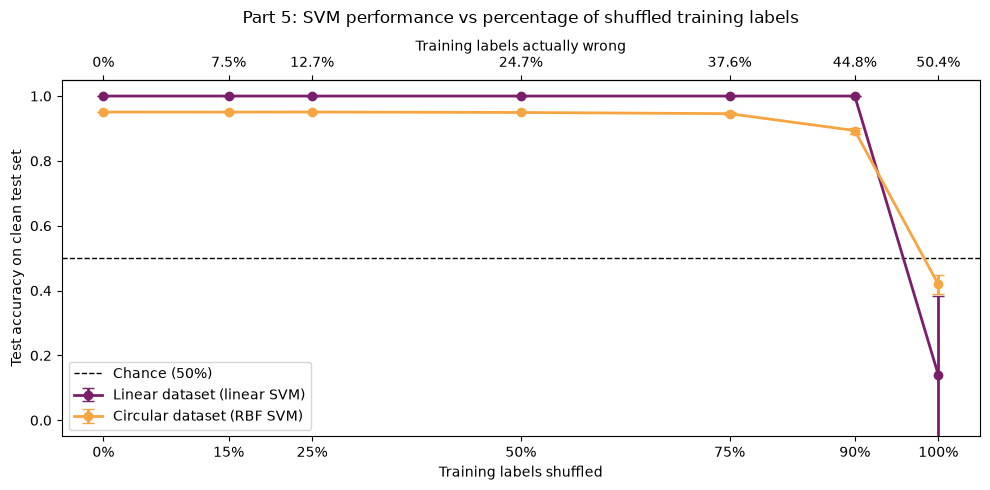

In [10]:
# ===== Part 5: label noise (shuffled training labels) =====
def shuffle_labels(y, frac, rng):
    """Pick a fraction of the labels at random and shuffle them among themselves."""
    y_noisy = y.copy()
    idx = rng.choice(len(y), size=int(frac * len(y)), replace=False)  # which labels get shuffled
    y_noisy[idx] = rng.permutation(y_noisy[idx])                      # mix them up
    return y_noisy

SHUFFLE_FRACS = [0, 0.15, 0.25, 0.50, 0.75, 0.90, 1.00]   # assignment: 15/25/50%; the rest show where it breaks
N_REPEATS = 3                                             # different random shuffles per level -> error bars

part5_setups = {
    "Linear dataset (linear SVM)": (X_lin_train, X_lin_test, y_lin_train, y_lin_test,
                                    lambda: SVC(kernel="linear", C=1.0)),
    "Circular dataset (RBF SVM)":  (X_circ_train, X_circ_test, y_circ_train, y_circ_test,
                                    lambda: SVC(kernel="rbf", gamma=1, C=10)),
}

rows = []
start = time.time()
for setup, (X_tr, X_te, y_tr, y_te, make_model) in part5_setups.items():
    for frac in SHUFFLE_FRACS:
        for rep in range(N_REPEATS):
            r = np.random.default_rng(SEED + rep)
            y_noisy = shuffle_labels(y_tr, frac, r)        # noise ONLY in the training labels
            model = make_model().fit(X_tr, y_noisy)
            y_pred = model.predict(X_te)                   # scored on the CLEAN test set
            rows.append({"Setup": setup, "Shuffled (%)": int(frac * 100), "Repeat": rep,
                         "Labels actually wrong (%)": 100 * (y_noisy != y_tr).mean(),
                         "Test accuracy": accuracy_score(y_te, y_pred),
                         "F1": f1_score(y_te, y_pred, zero_division=0)})
    print(f"{setup} done ({time.time() - start:.0f} s)")

part5_df = pd.DataFrame(rows)
part5_summary = (part5_df.groupby(["Setup", "Shuffled (%)"], sort=False)
                 [["Labels actually wrong (%)", "Test accuracy", "F1"]].agg(["mean", "std"]).round(3))
print(part5_summary)

# ---- Plot: performance vs % shuffled ----
fig, ax = plt.subplots(figsize=(10, 5))
line_colors = {"Linear dataset (linear SVM)": CLASS_COLORS[0],
               "Circular dataset (RBF SVM)":  CLASS_COLORS[1]}
for setup, col in line_colors.items():
    g = part5_df[part5_df["Setup"] == setup].groupby("Shuffled (%)")["Test accuracy"]
    ax.errorbar(g.mean().index, g.mean().values, yerr=g.std().values,
                marker="o", capsize=4, lw=2, color=col, label=setup)
ax.axhline(0.5, color="k", ls="--", lw=1, label="Chance (50%)")

# Bottom axis: % of training labels shuffled
wrong = part5_df.groupby("Shuffled (%)")["Labels actually wrong (%)"].mean()
ax.set_xticks(wrong.index)
ax.set_xticklabels([f"{s}%" for s in wrong.index])
ax.set_xlabel("Training labels shuffled")

# Top axis: % of training labels that actually became wrong (same positions)
top = ax.secondary_xaxis("top")
top.set_xticks(wrong.index)
top.set_xticklabels([f"{round(w, 1):g}%" for w in wrong.values])
top.set_xlabel("Training labels actually wrong")

ax.set_ylabel("Test accuracy on clean test set")
ax.set_ylim(-0.05, 1.05)
ax.set_title("Part 5: SVM performance vs percentage of shuffled training labels", pad=12)
ax.legend(loc="lower left")
fig.tight_layout()
fig.savefig("Figures/part5_label_noise.png", dpi=300)
plt.show()

Linear dataset (linear SVM): 2 dimensions done (6 s)
Linear dataset (linear SVM): 5 dimensions done (13 s)
Linear dataset (linear SVM): 10 dimensions done (21 s)
Linear dataset (linear SVM): 15 dimensions done (33 s)
Circular dataset (RBF SVM): 2 dimensions done (40 s)
Circular dataset (RBF SVM): 5 dimensions done (50 s)
Circular dataset (RBF SVM): 10 dimensions done (63 s)
Circular dataset (RBF SVM): 15 dimensions done (82 s)

Mean test accuracy (columns = % of training labels shuffled)
 Shuffled (%)                               0      15     25     50
Setup                       Dimensions                            
Circular dataset (RBF SVM)  2           0.950  0.950  0.950  0.949
                            5           0.948  0.941  0.940  0.921
                            10          0.934  0.908  0.899  0.854
                            15          0.925  0.889  0.877  0.794
Linear dataset (linear SVM) 2           1.000  1.000  1.000  1.000
                            5        

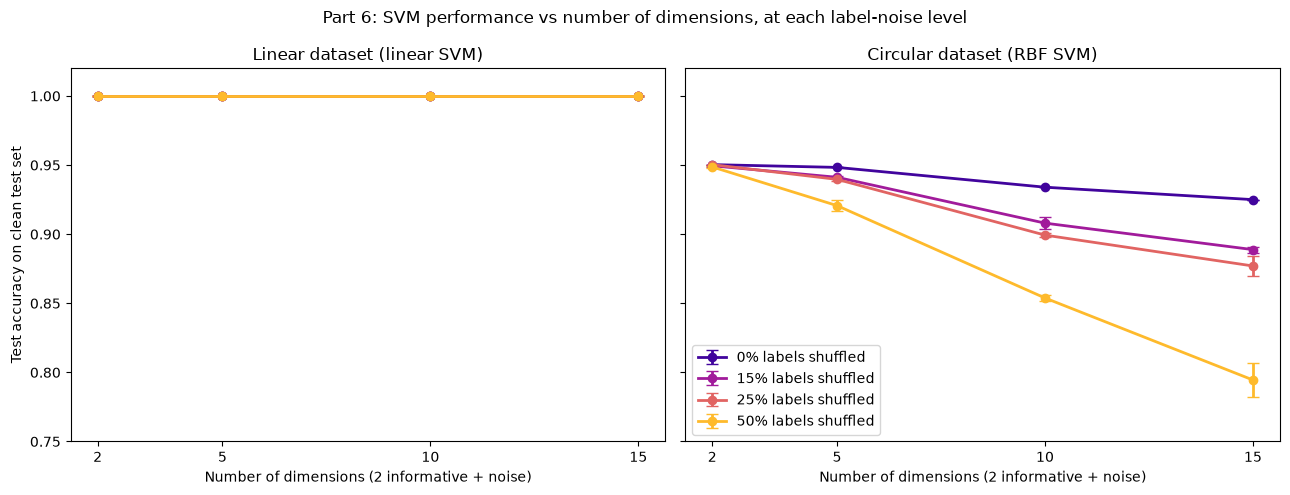

In [11]:
# ===== Part 6: higher dimensions (2 informative features + random noise features) =====
DIMS = [2, 5, 10, 15]
SHUFFLE_FRACS_6 = [0, 0.15, 0.25, 0.50]   # the label-noise levels from Part 5
N_REPEATS_6 = 2

dim_rng = np.random.default_rng(SEED + 100)
extra_all = dim_rng.normal(0, 1, size=(n, max(DIMS) - 2))   # 13 columns of pure noise, made once

part6_base = {
    "Linear dataset (linear SVM)": (X_lin,  y_lin,  lambda: SVC(kernel="linear", C=1.0)),
    "Circular dataset (RBF SVM)":  (X_circ, y_circ, lambda: SVC(kernel="rbf", gamma="scale", C=10)),
}

rows = []
start = time.time()
for setup, (X_base, y_base, make_model) in part6_base.items():
    for d in DIMS:
        X_d = np.hstack([X_base, extra_all[:, :d - 2]])     # columns 1-2 = real signal, the rest = noise
        X_tr, X_te, y_tr, y_te = train_test_split(X_d, y_base, test_size=TEST_SIZE,
                                                  random_state=SEED, stratify=y_base)
        for frac in SHUFFLE_FRACS_6:
            for rep in range(N_REPEATS_6):
                y_noisy = shuffle_labels(y_tr, frac, np.random.default_rng(SEED + rep))
                model = make_model().fit(X_tr, y_noisy)
                y_pred = model.predict(X_te)
                rows.append({"Setup": setup, "Dimensions": d, "Shuffled (%)": int(frac * 100),
                             "Repeat": rep,
                             "Test accuracy": accuracy_score(y_te, y_pred),
                             "F1": f1_score(y_te, y_pred, zero_division=0)})
        print(f"{setup}: {d} dimensions done ({time.time() - start:.0f} s)")

part6_df = pd.DataFrame(rows)
part6_table = part6_df.pivot_table(index=["Setup", "Dimensions"], columns="Shuffled (%)",
                                   values="Test accuracy", aggfunc="mean").round(3)
print("\nMean test accuracy (columns = % of training labels shuffled)\n", part6_table)

# ---- Plot: accuracy vs dimensions, one line per label-noise level ----
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
shuffle_colors = plt.get_cmap(SUNSET_CMAP)(np.linspace(0.1, 0.85, len(SHUFFLE_FRACS_6)))
for ax, setup in zip(axes, part6_base):
    sub = part6_df[part6_df["Setup"] == setup]
    for col, frac in zip(shuffle_colors, SHUFFLE_FRACS_6):
        g = sub[sub["Shuffled (%)"] == int(frac * 100)].groupby("Dimensions")["Test accuracy"]
        ax.errorbar(g.mean().index, g.mean().values, yerr=g.std().values, marker="o",
                    capsize=4, lw=2, color=col, label=f"{int(frac * 100)}% labels shuffled")
    ax.set_xticks(DIMS)
    ax.set_xlabel("Number of dimensions (2 informative + noise)")
    ax.set_title(setup)
axes[0].set_ylabel("Test accuracy on clean test set")
axes[0].set_ylim(0.75, 1.02)
axes[1].legend(loc="lower left")
fig.suptitle("Part 6: SVM performance vs number of dimensions, at each label-noise level")
fig.tight_layout()
fig.savefig("Figures/part6_high_dimensions.png", dpi=300)
plt.show()

SD = 0.1 done (24 s)
SD = 0.2 done (46 s)
SD = 0.3 done (64 s)
SD = 0.4 done (81 s)
SD = 0.5 done (97 s)
SD = 0.6 done (115 s)
SD = 0.7 done (133 s)
SD = 0.8 done (150 s)
SD = 0.9 done (167 s)
SD = 1.0 done (184 s)
SD = 1.1 done (201 s)
SD = 1.2 done (218 s)
SD = 1.3 done (235 s)

                Model  Noise SD where accuracy = 70%
    RBF best (γ = 1)                          0.779
RBF overfit (γ = 50)                          0.778
   Ideal circle rule                          0.783


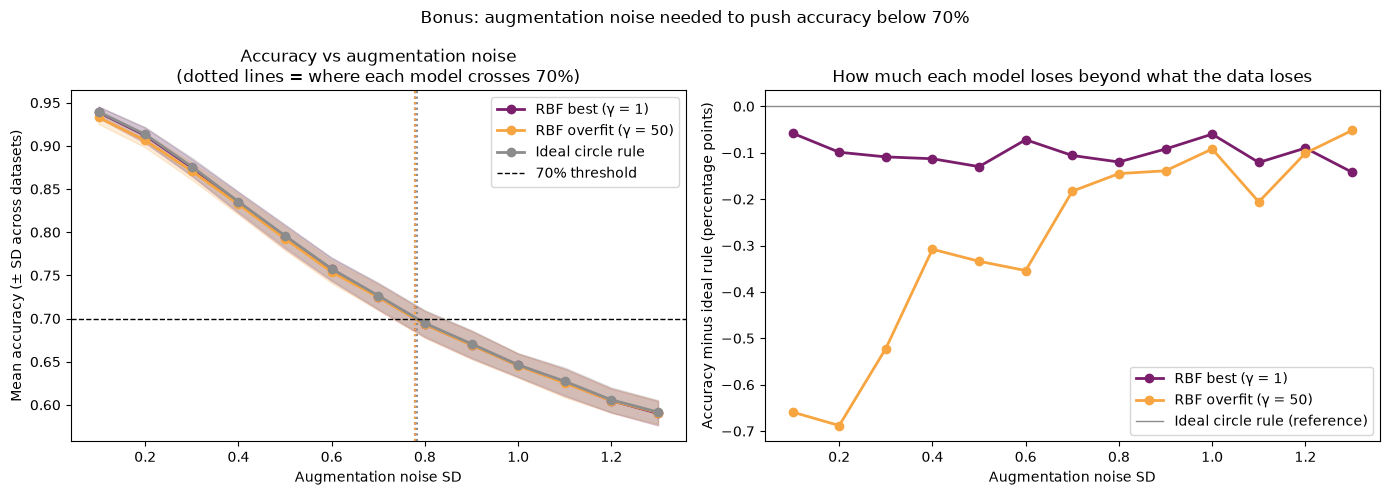

In [12]:
# ===== Bonus: noise level at which each model drops below 70% accuracy =====
THRESHOLD = 0.70
SD_GRID = np.round(np.arange(0.1, 1.31, 0.1), 2)   # augmentation noise levels: 0.1, 0.2, ..., 1.3
K_BONUS = 100                                      # augmented datasets per noise level

bonus_rng = np.random.default_rng(SEED)
rows = []
start = time.time()
for sd in SD_GRID:
    for k in range(K_BONUS):
        idx   = bonus_rng.choice(len(y_circ_test), size=N_SAMPLE, replace=False)
        X_aug = X_circ_test[idx] + bonus_rng.normal(0, sd, size=(N_SAMPLE, 2))
        y_aug = y_circ_test[idx]
        for name, predict in predictors.items():          # same 3 classifiers as Part 4
            rows.append({"Noise SD": sd, "Model": name,
                         "Accuracy": accuracy_score(y_aug, predict(X_aug))})
    print(f"SD = {sd} done ({time.time() - start:.0f} s)")
bonus_df = pd.DataFrame(rows)

stats = bonus_df.groupby(["Model", "Noise SD"])["Accuracy"].agg(["mean", "std"]).reset_index()

# ---- Where does each model cross 70%? (linear interpolation between grid points) ----
crossings = {}
for name in predictors:
    s = stats[stats["Model"] == name]
    crossings[name] = np.interp(THRESHOLD, s["mean"].values[::-1], s["Noise SD"].values[::-1])
crossing_df = pd.DataFrame({"Model": list(crossings),
                            "Noise SD where accuracy = 70%": np.round(list(crossings.values()), 3)})
print("\n", crossing_df.to_string(index=False))

# ---- Plot ----
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]                                   # accuracy vs noise, with the 70% threshold
for name, col in hist_colors.items():
    s = stats[stats["Model"] == name]
    ax.plot(s["Noise SD"], s["mean"], marker="o", lw=2, color=col, label=name)
    ax.fill_between(s["Noise SD"], s["mean"] - s["std"], s["mean"] + s["std"], color=col, alpha=0.2)
    ax.axvline(crossings[name], color=col, ls=":", lw=1.5)
ax.axhline(THRESHOLD, color="k", ls="--", lw=1, label="70% threshold")
ax.set_xlabel("Augmentation noise SD")
ax.set_ylabel("Mean accuracy (± SD across datasets)")
ax.set_title("Accuracy vs augmentation noise\n(dotted lines = where each model crosses 70%)")
ax.legend()

ax = axes[1]                                   # gap to the ideal rule: the cost of overfitting
ideal = stats[stats["Model"] == "Ideal circle rule"].set_index("Noise SD")["mean"]
for name in ["RBF best (γ = 1)", "RBF overfit (γ = 50)"]:
    s = stats[stats["Model"] == name].set_index("Noise SD")["mean"]
    ax.plot(s.index, 100 * (s - ideal), marker="o", lw=2, color=hist_colors[name], label=name)
ax.axhline(0, color="0.55", lw=1, label="Ideal circle rule (reference)")
ax.set_xlabel("Augmentation noise SD")
ax.set_ylabel("Accuracy minus ideal rule (percentage points)")
ax.set_title("How much each model loses beyond what the data loses")
ax.legend()

fig.suptitle(f"Bonus: augmentation noise needed to push accuracy below {THRESHOLD:.0%}")
fig.tight_layout()
fig.savefig("Figures/bonus_threshold.png", dpi=300)
plt.show()